# Лабораторная работа № 2. Свёрточные нейронные сети и регуляризация

**Тема:** свёрточные нейронные сети (CNN), пространственная структура изображений, нормализация и методы борьбы с переобучением.

**Цель:** освоить построение простых свёрточных нейронных сетей и понять преимущества свёрточных слоёв перед полносвязными сетями при обработке изображений.

В работе мы построим CNN-классификатор для изображений одежды Fashion-MNIST. Сначала разберём, почему полносвязная сеть не использует пространственную структуру изображения напрямую, как работают свёртки и pooling, а затем обучим простую CNN. После обучения исследуем переобучение и сравним несколько способов регуляризации: Dropout, Dropout2d и Batch Normalization.

In [ ]:
# Проверяем версии библиотек и выбираем устройство, на котором будут выполняться вычисления.
import sys
import platform
import torch

# Сначала фиксируем версии среды: это помогает понять, какие возможности PyTorch и CUDA доступны.
print(f"Python: {sys.version.split()[0]}")
print(f"Платформа: {platform.platform()}")
print(f"PyTorch: {torch.__version__}")
print(f"CUDA доступна: {torch.cuda.is_available()}")
print(f"CUDA-сборка PyTorch: {torch.version.cuda}")

# Выбираем единое устройство для дальнейших вычислений; при отсутствии CUDA используем CPU.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Устройство для вычислений: {device}")

# Дополнительные сведения о видеокарте выводим только тогда, когда CUDA действительно доступна.
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"CUDA-устройств: {torch.cuda.device_count()}")

## Что было рассмотрено в лабораторной работе № 1

В предыдущей работе мы строили многослойный перцептрон (MLP) для классификации изображений MNIST. Перед подачей в `nn.Linear` изображение размером $28\times28$ преобразовывалось в вектор длины 784:

$$
[1, 28, 28]\longrightarrow[784].
$$

Полносвязный слой связывает каждый входной признак с каждым нейроном следующего слоя. Например, слой `nn.Linear(784, 128)` содержит $784\cdot128+128$ обучаемых параметров.

Теперь рассмотрим другой подход: вместо того чтобы сразу связывать все пиксели со всеми нейронами, будем обрабатывать небольшие локальные области изображения и применять одни и те же фильтры в разных позициях.

## Ограничения MLP при обработке изображений

Преобразование изображения в вектор не удаляет значения пикселей, но **явно не сохраняет двумерную структуру** входа. Для MLP соседние элементы вектора - просто разные координаты признакового пространства. Сама сеть не получает специального указания, что два пикселя находились рядом на изображении.

У такого представления есть несколько особенностей:

- **Нет встроенной пространственной локальности.** Чтобы обнаружить небольшой контур или угол, MLP должен выучить связи между соответствующими позициями пикселей через веса полносвязных слоёв.
- **Нет совместного использования фильтров.** Для похожего признака в разных частях изображения полносвязная сеть может выучивать разные наборы весов.
- **Много параметров на ранних слоях.** При увеличении размера изображения число входных признаков растёт как $H\cdot W\cdot C$.
- **Чувствительность к положению признака.** Один и тот же локальный рисунок, сдвинутый на несколько пикселей, попадает в другие координаты входного вектора.

MLP может успешно классифицировать изображения, но не использует характерные для них свойства так эффективно, как CNN. Свёрточные сети вводят подходящее для изображений ограничение: сначала анализируются небольшие соседние области, а затем обнаруженные признаки объединяются в более сложные представления.

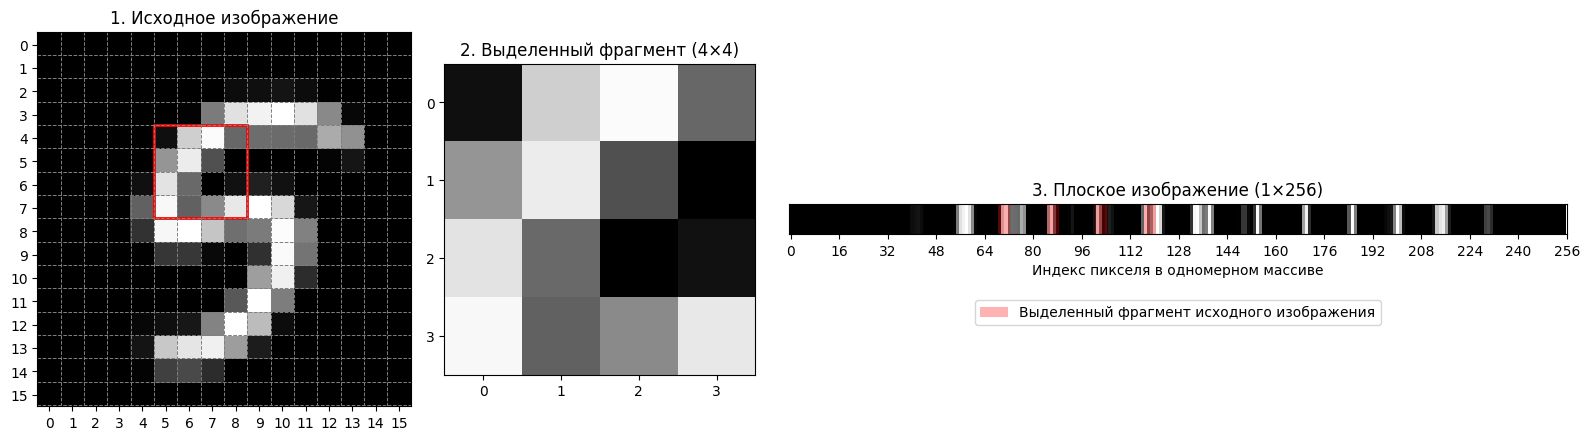

In [2]:
# Наглядная демонстрация нарушения двумерной структуры изображения при переходе к векторному представлению.
import base64
from io import BytesIO

import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

base64_string = "iVBORw0KGgoAAAANSUhEUgAAABAAAAAQCAAAAAA6mKC9AAAAhElEQVR4nGNgIAQYYQweZtYfX//DxZmrH376/7CTHaaC/4BODtu/f07P8qEKpr4JAFEsolC+wJMsBkFFQTCbCUQEivzoun7vuBjcSKPv/4/mV/9pRNhtZs7JYPirBNVF8z7ooPAj/tciOOz84i3/9/AgBEROPP0wVwbJL8y2nE8u4/ItAEb4J6WHGzsbAAAAAElFTkSuQmCC"

# Загружаем изображение.
image_data = base64.b64decode(base64_string)
image = Image.open(BytesIO(image_data)).convert("L")
img_np = np.array(image)

height, width = img_np.shape
flat = img_np.flatten()

# Область, которую будем выделять.
row_start, row_end = 4, 8
col_start, col_end = 5, 9

# Получаем выделенный фрагмент.
fragment = img_np[row_start:row_end, col_start:col_end]

# Индексы пикселей фрагмента в плоском массиве.
indices = [
    row * width + col
    for row in range(row_start, row_end)
    for col in range(col_start, col_end)
]

fig, ax = plt.subplots(
    1, 3, figsize=(16, 5), gridspec_kw={"width_ratios": [1.2, 1, 2.5]}
)

# 1. Исходное изображение.
ax[0].imshow(img_np, cmap="gray", vmin=0, vmax=255)

# Выделение области.
rect = patches.Rectangle(
    (col_start - 0.5, row_start - 0.55),
    col_end - col_start,
    row_end - row_start,
    linewidth=2,
    edgecolor="red",
    facecolor="none",
)
ax[0].add_patch(rect)

ax[0].set_title("1. Исходное изображение")

ax[0].set_xticks(range(width))
ax[0].set_yticks(range(height))
ax[0].set_xticks(np.arange(-0.5, width, 1), minor=True)
ax[0].set_yticks(np.arange(-0.5, height, 1) - 0.05, minor=True)

# Линии сетки пикселей.
ax[0].grid(which="minor", linestyle="--", color="gray", linewidth=0.7)
ax[0].tick_params(which="minor", bottom=False, left=False)

# 2. Увеличенный выделенный фрагмент.
ax[1].imshow(fragment, cmap="gray", vmin=0, vmax=255)
ax[1].set_title("2. Выделенный фрагмент (4×4)")
ax[1].set_xticks(range(fragment.shape[1]))
ax[1].set_yticks(range(fragment.shape[0]))

# 3. Плоское изображение.
ax[2].imshow(flat.reshape(1, -1), aspect=10, cmap="gray")

# Подсвечиваем соответствующие пиксели.
for idx in indices:
    rect = patches.Rectangle(
        (idx - 0.5, -0.5), 1, 1, linewidth=0, facecolor="red", alpha=0.3
    )
    ax[2].add_patch(rect)

ax[2].set_title("3. Плоское изображение (1×256)")
ax[2].set_yticks([])
ax[2].set_xticks(np.arange(0, width * height + 1, 16))
ax[2].legend(
    ["Выделенный фрагмент исходного изображения"],
    bbox_to_anchor=(0.5, -3),
    loc="lower center",
    borderaxespad=0,
)
ax[2].set_xlabel("Индекс пикселя в одномерном массиве")

plt.tight_layout()
plt.show()

## Свёрточная нейронная сеть (CNN)

**Свёрточная нейронная сеть** (*Convolutional Neural Network, CNN*) - нейронная сеть, в которой для обработки пространственных данных используются свёрточные слои. В изображениях соседние пиксели часто связаны между собой: локальные участки содержат границы, линии, текстуры и другие визуальные признаки.

Свёрточный слой применяет к локальным областям изображения небольшие обучаемые матрицы - **ядра свёртки** (*kernels* или *filters*). Одно ядро перемещается по изображению и вычисляет отклик для каждой позиции. В результате получается карта признаков (*feature map*).

Важное отличие от `nn.Linear`: веса одного фильтра используются во всех пространственных позициях. Это называется **разделением весов** (*weight sharing*). Благодаря этому один и тот же признак может обнаруживаться в разных частях изображения, а число параметров не зависит напрямую от ширины и высоты входа.

В глубоких CNN первые слои обычно находят простые локальные структуры, а последующие объединяют их в более сложные признаки. Например, сеть может последовательно перейти от контуров и текстур к частям объектов и целым объектам.

### Локальные рецептивные поля и пространственная локальность

**Рецептивное поле** нейрона - область входного изображения, от которой зависит его значение. У свёрточного слоя с ядром $3\times3$ каждый элемент выходной карты признаков зависит от локальной области из девяти пространственных позиций (с учётом всех входных каналов).

Для каждого положения ядра используются одни и те же коэффициенты. Если некоторый фильтр реагирует на вертикальную границу в левой части изображения, он может реагировать на аналогичную границу и в правой части.

Такое свойство делает свёртку подходящим инструментом для изображений. При этом свёрточный слой не становится полностью независимым от положения: границы изображения и padding влияют на обработку краевых областей, а последующие слои и классификатор могут учитывать расположение признаков.

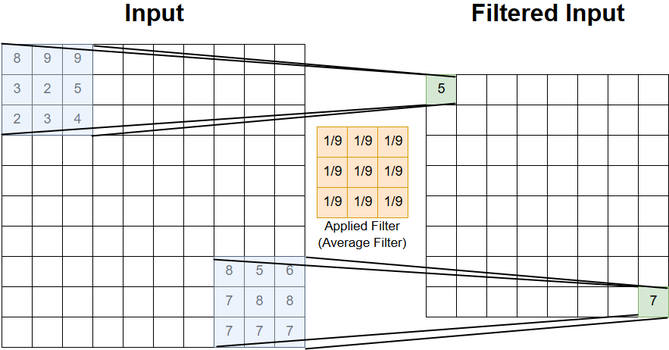

### Свёрточный слой, ядра и каналы

Пусть входной батч имеет форму:

$$
X\in\mathbb{R}^{B\times C_{in}\times H\times W},
$$

где $B$ - размер батча, $C_{in}$ - число входных каналов, $H$ и $W$ - высота и ширина изображения.

Слой `nn.Conv2d(in_channels, out_channels, kernel_size)` создаёт `out_channels` фильтров. Каждый фильтр учитывает **все входные каналы** и формирует один выходной канал. Поэтому весовой тензор имеет форму:

$$
(C_{out}, C_{in}, K_H, K_W).
$$

Если ядро квадратное и используется bias, число обучаемых параметров равно:

$$
N_{params}=C_{out}\cdot C_{in}\cdot K^2+C_{out}.
$$

Например, `nn.Conv2d(1, 32, kernel_size=3)` имеет $32\cdot1\cdot3\cdot3+32=320$ обучаемых параметров. Для `nn.Conv2d(32, 64, kernel_size=3)` их уже $64\cdot32\cdot3\cdot3+64=18\,496$.

**Каналы** можно понимать как отдельные карты признаков. Разные фильтры обучаются реагировать на разные визуальные структуры. Число каналов `out_channels` задаёт ширину представления, которое формирует слой.

В PyTorch для изображений используется порядок размерностей `NCHW`: batch, channels, height, width. Например, батч из 128 одноканальных изображений Fashion-MNIST имеет форму `(128, 1, 28, 28)`.

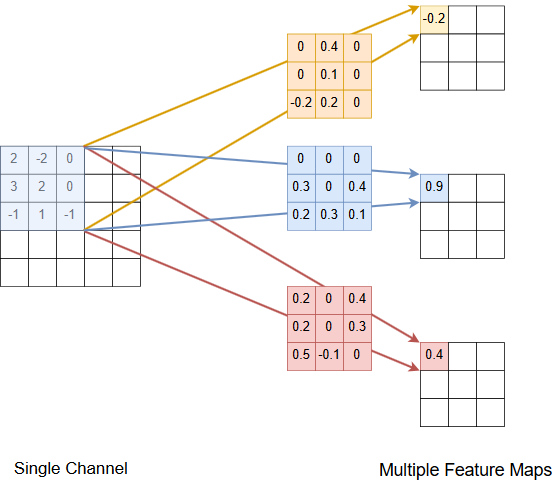

### Параметры `stride` и `padding`

**Stride** - шаг, с которым ядро перемещается по входному изображению.

- `stride=1`: ядро сдвигается на один пиксель; выходная карта получается более подробной.
- `stride=2`: ядро сдвигается на два пикселя; пространственное разрешение выхода обычно уменьшается.

**Padding** - добавление значений по краям входа перед свёрткой. Чаще всего используется нулевой padding.

- `padding=0`: ядро не выходит за границы исходного изображения, поэтому ширина и высота выхода уменьшаются.
- `padding=1` при ядре $3\times3$ и `stride=1`: добавляется по одному пикселю с каждой стороны, поэтому пространственный размер сохраняется.

Для квадратного ядра размером $K\times K$, одинаковых параметров по высоте и ширине и `dilation=1` размер выхода рассчитывается так:

$$
H_{out}=\left\lfloor\frac{H+2P-K}{S}\right\rfloor+1,
\qquad
W_{out}=\left\lfloor\frac{W+2P-K}{S}\right\rfloor+1,
$$

где $S$ - stride, $P$ - padding. При `stride=1`, нечётном ядре и `padding=K//2` размер обычно сохраняется.

<table style="background: white; color: black;">
  <tr>
    <td>
		<p>padding = 0, stride = 1</p>
        <image width="200" src="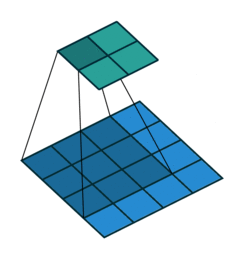"></image>
    </td>
	<td>
		<p>padding = 1, stride = 1</p>
        <image width="200" src="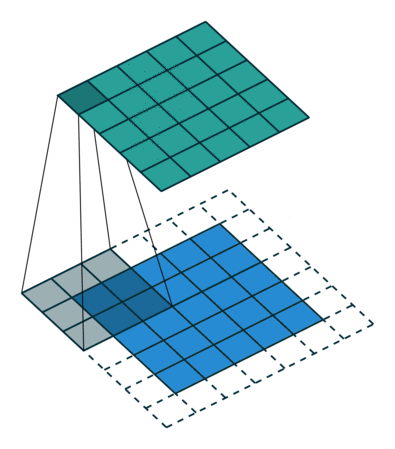"></image>
    </td>
  </tr>
  <tr>
	<td>
		<p>padding = 0, stride = 2</p>
        <image width="200" src="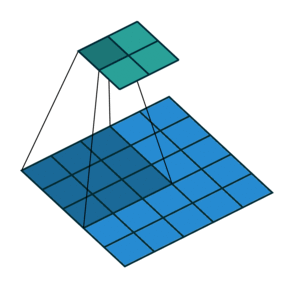"></image>
    </td>	
	<td>
		<p>padding = 1, stride = 2</p>
        <image width="200" src="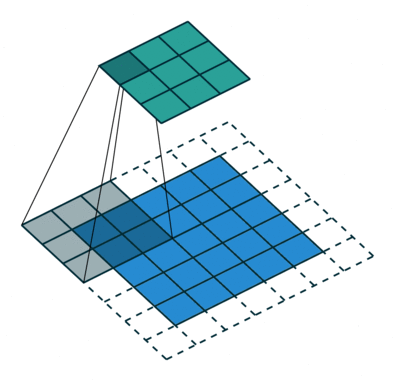"></image>
    </td>
  </tr>
</table

In [3]:
# Реализуем формулу размера выхода свёрточного слоя и проверяем несколько конфигураций.
def conv_output_size(
    input_size: int,
    kernel_size: int,
    stride: int = 1,
    padding: int = 0,
) -> int:
    """Вычисляет размер одной пространственной размерности после Conv2d."""
    return (input_size + 2 * padding - kernel_size) // stride + 1


configurations = [
    {"kernel_size": 3, "stride": 1, "padding": 0},
    {"kernel_size": 3, "stride": 1, "padding": 1},
    {"kernel_size": 3, "stride": 2, "padding": 1},
    {"kernel_size": 5, "stride": 1, "padding": 2},
]

for config in configurations:
    output_size = conv_output_size(28, **config)
    print(f"{config} -> {output_size} × {output_size}")

{'kernel_size': 3, 'stride': 1, 'padding': 0} -> 26 × 26
{'kernel_size': 3, 'stride': 1, 'padding': 1} -> 28 × 28
{'kernel_size': 3, 'stride': 2, 'padding': 1} -> 14 × 14
{'kernel_size': 5, 'stride': 1, 'padding': 2} -> 28 × 28


**Небольшое задание.** Не запуская код, рассчитайте размеры выхода для входа $28\times28$ в четырёх случаях:

1. $K=5$, `stride=1`, `padding=0`;
2. $K=5$, `stride=1`, `padding=2`;
3. $K=3$, `stride=2`, `padding=1`;
4. $K=3$, `stride=2`, `padding=0`.

Затем проверьте ответы с помощью `conv_output_size()`. Почему в первом и втором случаях выходы имеют разные размеры?

### Pooling и уменьшение пространственного разрешения

После свёрточных слоёв часто используют операции **pooling** - агрегирование значений в небольших пространственных областях. В этой работе будем использовать `nn.MaxPool2d(kernel_size=2, stride=2)`.

Max pooling делит карту признаков на неперекрывающиеся области $2\times2$ и оставляет максимальное значение в каждой области. Для входа $28\times28$ это даёт выход $14\times14$.

Pooling уменьшает пространственное разрешение и число значений, которые должны обрабатываться следующими слоями. Кроме того, небольшие изменения положения признака внутри области pooling могут не менять максимальное значение. У операции `MaxPool2d` нет обучаемых весов.

Pooling не заменяет свёртку: свёрточный слой обучает фильтры обнаруживать признаки, а pooling агрегирует уже полученные отклики.

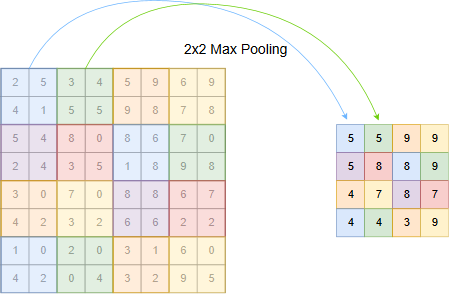

In [4]:
# Сравниваем исходную матрицу и результат MaxPool2d на небольшом примере.
from torch import nn

pooling_input = torch.tensor(
    [
        [
            [
                [1.0, 3.0, 2.0, 4.0],
                [5.0, 6.0, 1.0, 2.0],
                [0.0, 2.0, 7.0, 3.0],
                [4.0, 1.0, 5.0, 8.0],
            ]
        ]
    ]
)
pooling_output = nn.MaxPool2d(kernel_size=2, stride=2)(pooling_input)

print("Исходная матрица:")
print(pooling_input[0, 0])
print("\nПосле MaxPool2d:")
print(pooling_output[0, 0])
print("Форма до pooling:", tuple(pooling_input.shape))
print("Форма после pooling:", tuple(pooling_output.shape))

Исходная матрица:
tensor([[1., 3., 2., 4.],
        [5., 6., 1., 2.],
        [0., 2., 7., 3.],
        [4., 1., 5., 8.]])

После MaxPool2d:
tensor([[6., 4.],
        [4., 8.]])
Форма до pooling: (1, 1, 4, 4)
Форма после pooling: (1, 1, 2, 2)


**Исследование.** Для чего может быть полезно уменьшение пространственного разрешения? Какие детали изображения могут теряться при многократном pooling? Почему нельзя бездумно уменьшать карту признаков до размера $1\times1$ уже в первых слоях?

## Датасет Fashion-MNIST

Вместо рукописных цифр из MNIST будем классифицировать изображения предметов одежды из **Fashion-MNIST**. Набор содержит 10 классов, изображения имеют оттенки серого и размер $28\times28$ пикселей.

Классы Fashion-MNIST:

| Метка | Класс |
|---:|---|
| 0 | T-shirt/top |
| 1 | Trouser |
| 2 | Pullover |
| 3 | Dress |
| 4 | Coat |
| 5 | Sandal |
| 6 | Shirt |
| 7 | Sneaker |
| 8 | Bag |
| 9 | Ankle boot |

Сначала загрузим исходные данные и посмотрим на несколько примеров. На этом этапе не будем применять аугментации: в лабораторной важно отдельно исследовать архитектуру и регуляризацию.

## Воспроизводимость и параметры эксперимента

Зафиксируем seed и основные настройки. Это поможет сравнивать MLP, CNN и варианты регуляризации на одном и том же разбиении данных.

In [5]:
# Фиксируем seed и задаём основные гиперпараметры эксперимента в одном месте.
from pathlib import Path
import random

SEED = 42
BATCH_SIZE = 128
MAX_EPOCHS = 10
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
VALIDATION_SHARE = 0.20
DATA_DIR = Path("./data")

DATA_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

In [6]:
CLASS_NAMES = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot",
]

## Загрузка и визуализация Fashion-MNIST

Загрузим исходные изображения без автоматического преобразования. Объект `datasets.FashionMNIST` хранит изображения в `data`, а метки классов - в `targets`. Такой способ позволяет самостоятельно организовать разделение данных и подготовку батчей.

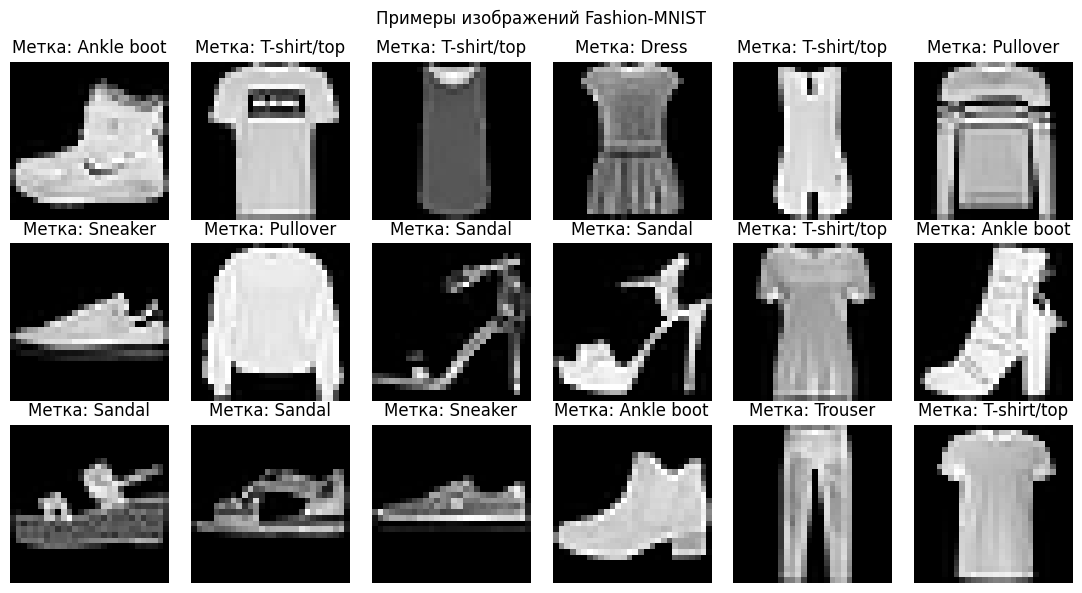

Размер обучающей части: 60000
Форма одного изображения: (28, 28)


In [7]:
# Загружаем Fashion-MNIST для первичного просмотра и выводим несколько изображений с метками.
from torchvision import datasets

train_raw = datasets.FashionMNIST(root=DATA_DIR, train=True, download=True)
test_raw = datasets.FashionMNIST(root=DATA_DIR, train=False, download=True)

fig, axes = plt.subplots(3, 6, figsize=(11, 6))
for index, ax in enumerate(axes.flat):
    image = train_raw.data[index]
    label = int(train_raw.targets[index])
    ax.imshow(image, cmap="gray")
    ax.set_title(f"Метка: {CLASS_NAMES[label]}")
    ax.axis("off")

fig.suptitle("Примеры изображений Fashion-MNIST")
plt.tight_layout()
plt.show()

print("Размер обучающей части:", len(train_raw))
print("Форма одного изображения:", tuple(train_raw.data[0].shape))

### Баланс классов

Проверим количество объектов каждого класса в обучающей части. Это полезно сделать до обучения: сильный дисбаланс может влиять на интерпретацию accuracy и других метрик.

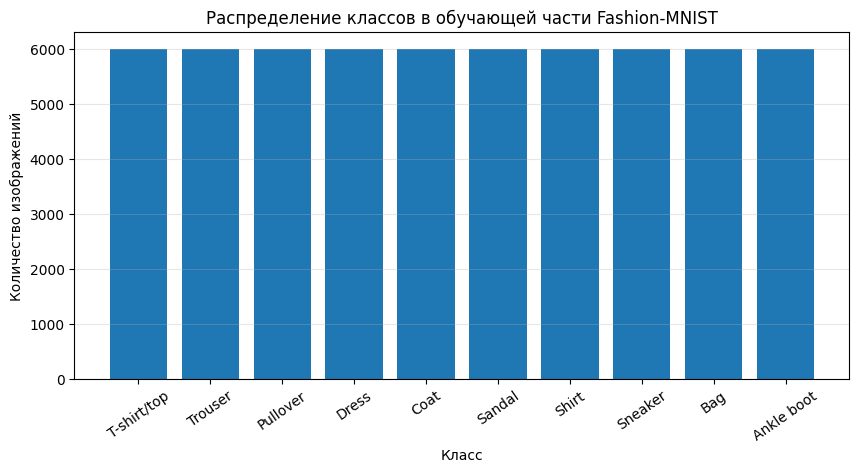

{'T-shirt/top': 6000, 'Trouser': 6000, 'Pullover': 6000, 'Dress': 6000, 'Coat': 6000, 'Sandal': 6000, 'Shirt': 6000, 'Sneaker': 6000, 'Bag': 6000, 'Ankle boot': 6000}


In [8]:
# Подсчитываем количество объектов каждого класса в исходной обучающей части Fashion MNIST.
class_counts = torch.bincount(train_raw.targets, minlength=10).numpy()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(CLASS_NAMES, class_counts)
ax.set_xlabel("Класс")
ax.set_ylabel("Количество изображений")
ax.set_title("Распределение классов в обучающей части Fashion-MNIST")
ax.tick_params(axis="x", rotation=35)
ax.grid(axis="y", alpha=0.3)
plt.show()

print(dict(zip(CLASS_NAMES, class_counts.tolist())))

## Dataset, DataLoader и подготовка батчей на GPU

В предыдущей лабораторной работе мы отделяли исходные данные от преобразований, которые выполнялись при формировании батча. Здесь воспользуемся таким же принципом.

- `TensorDataset` хранит исходные изображения и метки. Изображения остаются в формате `uint8` на CPU и не нормализуются заранее.
- `DataLoader` выбирает индексы объектов и собирает элементы в список батча.
- `collate_fn` объединяет изображения в тензор, добавляет размерность канала, переносит данные на `device`, переводит пиксели в диапазон $[0,1]$ и выполняет нормализацию.

В работе используем стандартные статистики Fashion-MNIST: `mean = 0.2860` и `std = 0.3530`.

Последовательность для изображений:

$$
[B,28,28]\;\text{uint8}
\rightarrow [B,1,28,28]\;\text{float32}
\rightarrow \text{перенос на device}
\rightarrow \text{деление на }255
\rightarrow \text{Normalize}.
$$

В отличие от лабораторной № 1, здесь нет аугментации и нет преобразования `Flatten`: CNN должна получить двумерные карты пикселей с формой `[B, 1, 28, 28]`.

Все три DataLoader используют один collator и возвращают батчи на `device`. Поэтому `num_workers=0`: перенос CUDA-тензоров внутри `collate_fn` выполняется в основном процессе, без создания дополнительных процессов загрузки данных.

In [9]:
# Создаём collate_fn: он объединяет raw-изображения, переносит батч на device и нормализует пиксели.
from typing import TypeAlias, Union

NORMALIZE_MEAN = 0.2860
NORMALIZE_STD = 0.3530

# Один элемент батча: изображение и соответствующая ему метка.
TensorPair: TypeAlias = tuple[torch.Tensor, torch.Tensor]

# Устройство можно задать строкой, объектом torch.device или индексом GPU.
DeviceLikeType: TypeAlias = Union[str, torch.device, int]


class FashionMNISTCollator:
    """Подготавливает батч изображений Fashion-MNIST для CNN."""

    def __init__(self, device: DeviceLikeType) -> None:
        # Сохраняем целевое устройство, на котором будут выполняться преобразования.
        self.device = torch.device(device)

        self.mean = torch.tensor(
            NORMALIZE_MEAN,
            dtype=torch.float32,
            device=device,
        ).view(1, 1, 1, 1)
        self.std = torch.tensor(
            NORMALIZE_STD,
            dtype=torch.float32,
            device=device,
        ).view(1, 1, 1, 1)

    def __call__(self, batch: list[TensorPair]) -> TensorPair:
        # Разделяем список элементов батча на изображения и соответствующие метки.
        images, targets = zip(*batch)

        # Объединяем изображения в тензор [B, H, W] и добавляем размерность канала.
        # Одновременно получаем форму [B, 1, H, W].
        images = torch.stack(images).unsqueeze(1)

        # Переносим изображения на выбранное устройство и преобразуем в float32.
        # Деление на 255 переводит значения пикселей из [0, 255] в [0, 1].
        images = images.to(device=self.device, dtype=torch.float32) / 255.0

        # Объединяем метки в один тензор и переносим их на то же устройство.
        targets = torch.stack(targets).to(self.device)

        # Нормализуем по статистикам Fashion-MNIST; broadcast применяется ко всему батчу.
        images = (images - self.mean) / self.std

        # Возвращаем готовый батч признаков и меток.
        return images, targets

## Разделение на train, validation и test

- **train** используется для вычисления градиентов и обновления параметров;
- **validation** используется для наблюдения за качеством и выбора настроек;
- **test** используется для итоговой оценки уже выбранной модели.

Выделим 20% официальной обучающей части Fashion-MNIST под validation. Официальную тестовую часть не используем до финальной оценки.

In [10]:
# Разделяем обучающую часть Fashion MNIST на train и validation, сохраняя test отдельно.
from torch.utils.data import DataLoader, TensorDataset, Subset

train_full_dataset = TensorDataset(train_raw.data, train_raw.targets.long())
test_dataset = TensorDataset(test_raw.data, test_raw.targets.long())

split_generator = torch.Generator().manual_seed(SEED)
permuted_indices = torch.randperm(
    len(train_full_dataset), generator=split_generator
).tolist()

validation_size = int(len(permuted_indices) * VALIDATION_SHARE)
validation_indices = permuted_indices[:validation_size]
train_indices = permuted_indices[validation_size:]

train_dataset = Subset(train_full_dataset, train_indices)
validation_dataset = Subset(train_full_dataset, validation_indices)

print("Train:", len(train_dataset))
print("Validation:", len(validation_dataset))
print("Test:", len(test_dataset))

Train: 48000
Validation: 12000
Test: 10000


In [11]:
# Создаём все DataLoader с одним collator.
collator = FashionMNISTCollator(device=device)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
    num_workers=0,
    collate_fn=collator,
)
validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    collate_fn=collator,
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    collate_fn=collator,
)

features_batch, labels_batch = next(iter(train_loader))
print("Форма признаков:", tuple(features_batch.shape))
print("Форма меток:", tuple(labels_batch.shape))
print("Тип признаков:", features_batch.dtype)
print("Тип меток:", labels_batch.dtype)

Форма признаков: (128, 1, 28, 28)
Форма меток: (128,)
Тип признаков: torch.float32
Тип меток: torch.int64


## Архитектура простого CNN-классификатора

Построим сеть из двух свёрточных блоков и классификатора. Каждый блок содержит:

1. свёрточный слой `nn.Conv2d`;
2. нелинейность `nn.ReLU`;
3. `nn.MaxPool2d` для уменьшения пространственного разрешения.

После двух блоков тензор преобразуется в вектор, который обрабатывает небольшой полносвязный классификатор.

Для входа Fashion-MNIST размерности `[B, 1, 28, 28]` формы будут изменяться следующим образом:

| Этап | Форма тензора |
|---|---|
| Вход | `[B, 1, 28, 28]` |
| Conv2d: 1 → 32, $3\times3$, padding=1 | `[B, 32, 28, 28]` |
| ReLU | `[B, 32, 28, 28]` |
| MaxPool2d: $2\times2$ | `[B, 32, 14, 14]` |
| Conv2d: 32 → 64, $3\times3$, padding=1 | `[B, 64, 14, 14]` |
| ReLU | `[B, 64, 14, 14]` |
| MaxPool2d: $2\times2$ | `[B, 64, 7, 7]` |
| Flatten | `[B, 3136]` |
| Linear: 3136 → 128 | `[B, 128]` |
| Linear: 128 → 10 | `[B, 10]` |

Последний слой возвращает **логиты** для десяти классов. Softmax отдельно применять не нужно: `LitModel` использует `CrossEntropyLoss`, которая принимает логиты.

In [12]:
# Определяем CNN; значения параметров по умолчанию в точности задают базовую архитектуру из задания.
class FashionCNN(nn.Module):
    """Свёрточный классификатор Fashion-MNIST с настраиваемой регуляризацией."""

    def __init__(
        self,
        num_classes: int = 10,
        channels: tuple[int, int] = (32, 64),
        kernel_size: int = 3,
        stride: int = 1,
        use_batch_norm: bool = False,
        dropout_type: str = "none",
        dropout_p: float = 0.25,
    ) -> None:
        super().__init__()

        if kernel_size % 2 == 0:
            raise ValueError("Для этой реализации используйте нечётный kernel_size.")
        if dropout_type not in {"none", "dropout", "dropout2d"}:
            raise ValueError("dropout_type должен быть none, dropout или dropout2d.")

        padding = kernel_size // 2
        channels_1, channels_2 = channels

        # В базовом режиме этот блок совпадает с Conv2d -> ReLU -> MaxPool2d.
        block1_layers: list[nn.Module] = [
            nn.Conv2d(
                1,
                channels_1,
                kernel_size,
                stride=stride,
                padding=padding,
            )
        ]
        if use_batch_norm:
            block1_layers.append(nn.BatchNorm2d(channels_1))
        block1_layers.extend([nn.ReLU(), nn.MaxPool2d(kernel_size=2, stride=2)])
        self.block1 = nn.Sequential(*block1_layers)

        # Второй блок получает карты признаков первого блока и увеличивает число каналов.
        block2_layers: list[nn.Module] = [
            nn.Conv2d(
                channels_1,
                channels_2,
                kernel_size,
                stride=stride,
                padding=padding,
            )
        ]
        if use_batch_norm:
            block2_layers.append(nn.BatchNorm2d(channels_2))
        block2_layers.extend([nn.ReLU(), nn.MaxPool2d(kernel_size=2, stride=2)])
        self.block2 = nn.Sequential(*block2_layers)

        # Вычисляем пространственный размер после двух свёрток и двух pooling.
        spatial_size = 28
        for _ in range(2):
            spatial_size = (spatial_size + 2 * padding - kernel_size) // stride + 1
            spatial_size = (spatial_size - 2) // 2 + 1
        if spatial_size < 1:
            raise ValueError("Параметры свёрток слишком сильно уменьшают изображение.")

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(channels_2 * spatial_size * spatial_size, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes),
        )

        # Dropout применяется к картам признаков после каждого свёрточного блока.
        if dropout_type == "dropout":
            self.dropout1 = nn.Dropout(p=dropout_p)
            self.dropout2 = nn.Dropout(p=dropout_p)
        elif dropout_type == "dropout2d":
            self.dropout1 = nn.Dropout2d(p=dropout_p)
            self.dropout2 = nn.Dropout2d(p=dropout_p)
        else:
            self.dropout1 = nn.Identity()
            self.dropout2 = nn.Identity()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Возвращает логиты формы [batch_size, num_classes]."""
        x = self.dropout1(self.block1(x))
        x = self.dropout2(self.block2(x))
        return self.classifier(x)

In [13]:
# Проверяем формы выходов базовой CNN и убеждаемся, что сеть возвращает десять логитов.
cnn_model = FashionCNN().to(device)
example_images = torch.randn(4, 1, 28, 28, device=device)
example_logits = cnn_model(example_images)

print(cnn_model)
print("Форма входа:", tuple(example_images.shape))
print("Форма выхода:", tuple(example_logits.shape))

FashionCNN(
  (block1): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
  (dropout1): Identity()
  (dropout2): Identity()
)
Форма входа: (4, 1, 28, 28)
Форма выхода: (4, 10)


In [14]:
# Подсчитываем обучаемые параметры базовой CNN и каждого основного компонента.
def count_parameters(model: nn.Module) -> int:
    """Возвращает число обучаемых параметров модели."""
    return sum(
        parameter.numel() for parameter in model.parameters() if parameter.requires_grad
    )


for module_name, module in [
    ("block1", cnn_model.block1),
    ("block2", cnn_model.block2),
    ("classifier", cnn_model.classifier),
]:
    print(f"{module_name}: {count_parameters(module):,}")
print(f"Всего: {count_parameters(cnn_model):,} обучаемых параметров")

block1: 320
block2: 18,496
classifier: 402,826
Всего: 421,642 обучаемых параметров


**Небольшое задание.** Объясните, откуда берётся размер 3136 перед первым `Linear`. Рассчитайте число параметров каждого `Conv2d` и `Linear` вручную и сравните результат с `count_parameters()`.

## Обучение через PyTorch Lightning

В лабораторной работе № 1 мы использовали универсальный `LitModel`, вынесенный в отдельный модуль `lit.py`. Он принимает класс архитектуры, создаёт модель, задаёт `CrossEntropyLoss`, использует AdamW и организует обучение и валидацию.

In [ ]:
%pip install lightning -qU

In [15]:
import os
import sys

sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..")))

Обучим базовую архитектуру в течение **10 эпох**. В `lit.py` используется EarlyStopping, поэтому передадим `patience=MAX_EPOCHS`: это не позволит остановить данный запуск раньше заданного максимального числа эпох из-за обычного условия ранней остановки.

In [16]:
# Создаём базовую CNN и обучаем её с помощью универсального LitModel.
from templates.lit import LitModel

lit_model = LitModel(
    model=FashionCNN,
    num_classes=10,
    channels=(32, 64),
    kernel_size=3,
    stride=1,
    use_batch_norm=False,
    dropout_type="none",
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    seed=SEED,
)

metrics = lit_model.fit(
    train_loader=train_loader,
    validation_loader=validation_loader,
    epochs=MAX_EPOCHS,
    patience=MAX_EPOCHS,
)

best_model = lit_model.to(device).model.eval()

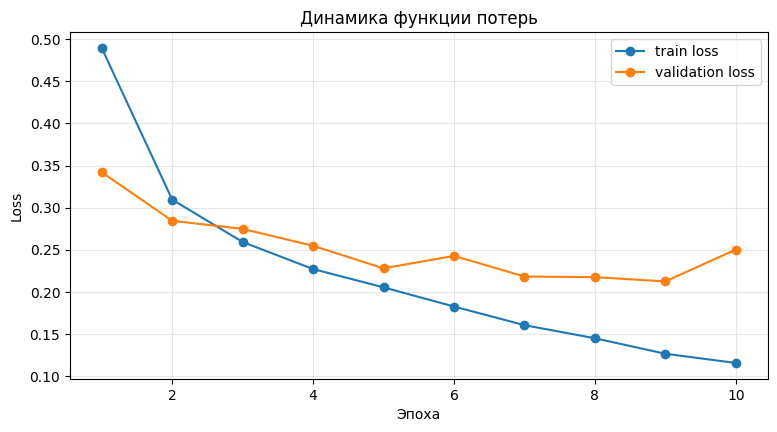

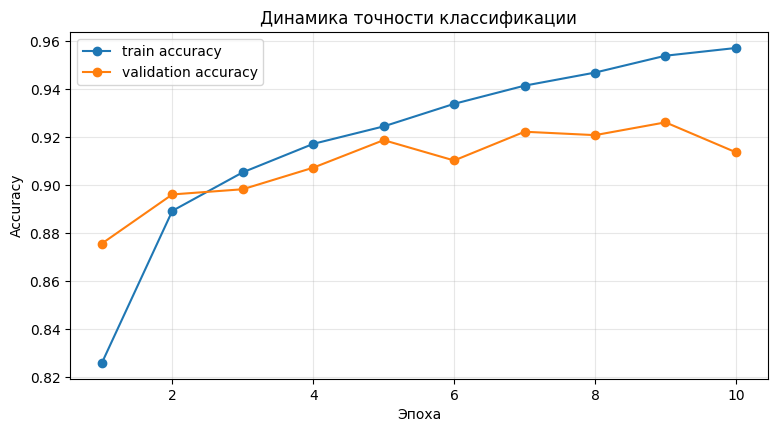

In [17]:
# Для каждой эпохи берём последнее доступное значение каждой метрики, пропуски игнорируются.
epoch_metrics = metrics.groupby("epoch")[
    ["train_loss", "train_accuracy", "val_loss", "val_accuracy"]
].last()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(
    epoch_metrics.index + 1, epoch_metrics["train_loss"], marker="o", label="train loss"
)
ax.plot(
    epoch_metrics.index + 1,
    epoch_metrics["val_loss"],
    marker="o",
    label="validation loss",
)
ax.set(xlabel="Эпоха", ylabel="Loss", title="Динамика функции потерь")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(
    epoch_metrics.index + 1,
    epoch_metrics["train_accuracy"],
    marker="o",
    label="train accuracy",
)
ax.plot(
    epoch_metrics.index + 1,
    epoch_metrics["val_accuracy"],
    marker="o",
    label="validation accuracy",
)
ax.set(xlabel="Эпоха", ylabel="Accuracy", title="Динамика точности классификации")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## Переобучение и обобщающая способность

**Переобучение** (*overfitting*) возникает, когда модель всё лучше описывает обучающие примеры, но это улучшение не переносится на новые данные. Модель может запоминать частные особенности обучающей выборки, шум и случайные детали.

Один из основных признаков переобучения - расхождение кривых обучения:

- `train_loss` продолжает уменьшаться, а `val_loss` перестаёт уменьшаться или начинает расти;
- `train_accuracy` продолжает увеличиваться, а `val_accuracy` выходит на плато или ухудшается;
- разрыв между обучающей и валидационной метриками становится заметнее.

Высокая точность на train сама по себе не означает, что модель хорошо обобщает. Для оценки важны результаты на данных, которые не участвовали в обновлении весов.

**Исследование.** Найдите эпоху с минимальным `val_loss`. Сравните её с последней эпохой. Есть ли разрыв между train и validation? Наблюдается ли момент, после которого качество на validation перестаёт улучшаться? Запишите наблюдения до экспериментов с регуляризацией.

## Dropout и Dropout2d

**Dropout** - способ регуляризации, при котором во время обучения случайная часть активаций зануляется. Это мешает сети чрезмерно полагаться на отдельные нейроны и стимулирует распределять информацию между признаками.

Для вероятности зануления $p$ каждый элемент независимо остаётся активным с вероятностью $1-p$. В стандартной реализации оставшиеся значения масштабируются на $1/(1-p)$, чтобы математическое ожидание активаций сохранялось.

В PyTorch:

- `nn.Dropout(p)` зануляет отдельные элементы входного тензора независимо друг от друга;
- `nn.Dropout2d(p)` для тензора формы `[B, C, H, W]` зануляет целые каналы (карты признаков) для отдельных объектов батча.

Оба слоя не содержат обучаемых параметров. `Dropout2d` особенно естественно использовать после свёрточных блоков: он отключает целые карты признаков, а не отдельные пиксели внутри каждой карты.

### Поведение Dropout в режимах `train()` и `eval()`

Dropout должен случайно занулять активации только во время обучения:

- в режиме `train()` при каждом проходе создаётся новая маска;
- в режиме `eval()` Dropout становится тождественным преобразованием и не зануляет значения.

PyTorch автоматически переключает поведение модулей при вызове `model.train()` и `model.eval()`. Это важно не только для Dropout, но и для Batch Normalization.

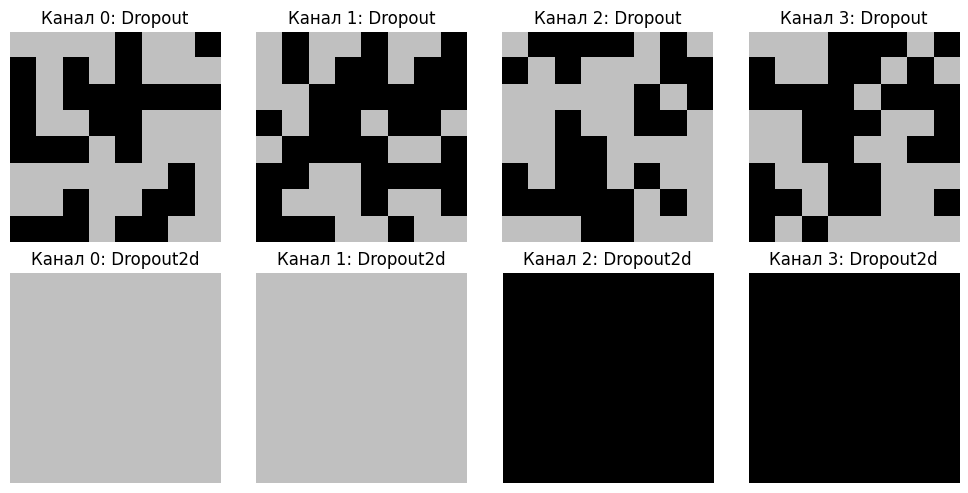

Доля нулевых элементов Dropout: 0.4921875
Доля нулевых элементов Dropout2d: 0.5


In [19]:
# Сравниваем маски обычного Dropout и Dropout2d на четырёх картах признаков.
torch.manual_seed(1)  # seed подобран для более наглядной визуализации.
feature_maps = torch.full((1, 4, 8, 8), 0.75)

ordinary_dropout = nn.Dropout(p=0.5).train()
channel_dropout = nn.Dropout2d(p=0.5).train()
ordinary_result = ordinary_dropout(feature_maps)
channel_result = channel_dropout(feature_maps)

fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for channel_index in range(4):
    axes[0, channel_index].imshow(
        ordinary_result[0, channel_index], cmap="gray", vmin=0, vmax=2
    )
    axes[0, channel_index].set_title(f"Канал {channel_index}: Dropout")
    axes[1, channel_index].imshow(
        channel_result[0, channel_index], cmap="gray", vmin=0, vmax=2
    )
    axes[1, channel_index].set_title(f"Канал {channel_index}: Dropout2d")
    axes[0, channel_index].axis("off")
    axes[1, channel_index].axis("off")
axes[0, 0].set_ylabel("Поэлементный")
axes[1, 0].set_ylabel("По каналам")
plt.tight_layout()
plt.show()

print("Доля нулевых элементов Dropout:", float((ordinary_result == 0).float().mean()))
print("Доля нулевых элементов Dropout2d:", float((channel_result == 0).float().mean()))

In [20]:
# Проверяем, что Dropout активен в train() и отключается в eval().
dropout_demo = nn.Dropout(p=0.5)
demo_input = torch.ones(12)

dropout_demo.train()
train_output_1 = dropout_demo(demo_input)
train_output_2 = dropout_demo(demo_input)

dropout_demo.eval()
eval_output = dropout_demo(demo_input)

print("Вход:", demo_input)
print("Train, проход 1:", train_output_1)
print("Train, проход 2:", train_output_2)
print("Eval:", eval_output)

Вход: tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])
Train, проход 1: tensor([2., 0., 2., 0., 2., 0., 0., 2., 0., 2., 2., 2.])
Train, проход 2: tensor([0., 2., 2., 2., 0., 0., 2., 0., 2., 2., 2., 2.])
Eval: tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])


**Исследование.** Сравните две визуализации масок. Почему Dropout2d удаляет больше связанной пространственной информации за один шаг? В каких случаях такой способ зануления может оказаться полезнее, а в каких - слишком сильным?

## Batch Normalization

**Batch Normalization (BatchNorm)** нормализует активации по статистикам мини-батча, а затем применяет обучаемые масштаб и смещение. Для свёрточных сетей обычно используют `nn.BatchNorm2d(C)`, где $C$ - число каналов.

Для каждого канала вычисляются среднее и дисперсия по объектам батча и пространственным позициям $H\times W$:

$$
\hat{x}=\frac{x-\mu_B}{\sqrt{\sigma_B^2+\varepsilon}},
\qquad y=\gamma\hat{x}+\beta.
$$

Здесь $\mu_B$ и $\sigma_B^2$ - среднее и дисперсия текущего батча, $\varepsilon$ - небольшое число для численной устойчивости, а $\gamma$ и $\beta$ - обучаемые параметры канала.

BatchNorm помогает стабилизировать распределение активаций и часто ускоряет обучение. Шум оценок статистик на мини-батчах может оказывать дополнительный регуляризующий эффект, однако BatchNorm не следует считать гарантированным способом устранения переобучения.

В этой работе `BatchNorm2d` расположен после свёртки и перед ReLU.

### Поведение BatchNorm в режимах `train()` и `eval()`

Режим работы BatchNorm отличается от Dropout:

- в `train()` используются статистики текущего батча, а скользящие оценки `running_mean` и `running_var` обновляются;
- в `eval()` используются накопленные `running_mean` и `running_var`, а не статистики текущего входного батча.

Поэтому перед оценкой модели на validation/test необходимо переключить её в `eval()`. В `LitModel` это выполняет Lightning во время validation и test шагов.

In [21]:
# Показываем, как BatchNorm обновляет running statistics в train() и использует их в eval().
batch_norm_demo = nn.BatchNorm2d(2)
bn_input = torch.randn(16, 2, 8, 8) * 3.0 + 2.0

initial_running_mean = batch_norm_demo.running_mean.clone()
batch_norm_demo.train()
bn_train_output = batch_norm_demo(bn_input)
updated_running_mean = batch_norm_demo.running_mean.clone()

batch_norm_demo.eval()
bn_eval_output = batch_norm_demo(bn_input)

print("Running mean до train:", initial_running_mean)
print("Running mean после train:", updated_running_mean)
print("Среднее выходов train по каналам:", bn_train_output.mean(dim=(0, 2, 3)))
print("Среднее выходов eval по каналам:", bn_eval_output.mean(dim=(0, 2, 3)))

Running mean до train: tensor([0., 0.])
Running mean после train: tensor([0.1859, 0.1940])
Среднее выходов train по каналам: tensor([ 5.3551e-09, -3.7253e-09], grad_fn=<MeanBackward1>)
Среднее выходов eval по каналам: tensor([1.2586, 1.3441], grad_fn=<MeanBackward1>)


**Небольшое задание.** Объясните, почему `running_mean` меняется при вызове BatchNorm в режиме `train()`, но не должен изменяться при `eval()`. Что может произойти, если перед тестированием забыть вызвать `model.eval()`?

## Сравнение MLP и CNN

CNN сохраняет пространственные размерности до тех пор, пока свёрточные и pooling-слои не преобразуют карту признаков. MLP получает тот же набор пикселей в виде одномерного вектора.

Для корректного сравнения используем одинаковые train/validation-разбиение, нормализацию, размер батча, оптимизатор и максимальное число эпох. В качестве MLP возьмём архитектуру из предыдущей лабораторной: два скрытых слоя на 256 и 128 нейронов.

Сравним:

- число обучаемых параметров;
- лучшую validation accuracy;
- значение validation loss.

Сравнение числа параметров не означает, что модель с большим количеством параметров обязательно будет точнее. Важно учитывать, как именно архитектура использует структуру данных.

In [22]:
# Определяем MLP для Fashion-MNIST с такой же размерностью скрытых слоёв, как в лабораторной № 1.
class FashionMLP(nn.Module):
    """Полносвязный классификатор для изображений 28 × 28."""

    def __init__(self, num_classes: int = 10) -> None:
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Преобразует батч изображений в логиты классов."""
        return self.network(x)

In [23]:
# Обучаем MLP тем же способом и с теми же параметрами обучения, что и базовую CNN.
mlp_lit_model = LitModel(
    model=FashionMLP,
    num_classes=10,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    seed=SEED,
)

mlp_metrics = mlp_lit_model.fit(
    train_loader=train_loader,
    validation_loader=validation_loader,
    epochs=MAX_EPOCHS,
    patience=MAX_EPOCHS,
)
mlp_best_model = mlp_lit_model.to(device).model.eval()

In [24]:
# Сравниваем количество параметров и лучшие значения validation-метрик MLP и CNN.
import pandas as pd


def summarize_history(history_df: pd.DataFrame) -> dict[str, float | int]:
    """Возвращает эпоху минимального val_loss и максимальную validation accuracy."""
    per_epoch = history_df.groupby("epoch")[
        ["train_loss", "train_accuracy", "val_loss", "val_accuracy"]
    ].last()
    best_loss_epoch = int(per_epoch["val_loss"].idxmin())
    return {
        "best_loss_epoch": best_loss_epoch + 1,
        "best_val_loss": float(per_epoch.loc[best_loss_epoch, "val_loss"]),
        "best_val_accuracy": float(per_epoch["val_accuracy"].max()),
    }


comparison = pd.DataFrame(
    [
        {
            "Модель": "MLP",
            "Параметры": count_parameters(mlp_best_model),
            **summarize_history(mlp_metrics),
        },
        {
            "Модель": "CNN",
            "Параметры": count_parameters(best_model),
            **summarize_history(metrics),
        },
    ]
)
comparison

,Модель,Параметры,best_loss_epoch,best_val_loss,best_val_accuracy
0,MLP,235146,5,0.310123,0.889417
1,CNN,421642,9,0.212511,0.926250


**Исследование.** Сравните MLP и CNN по числу параметров и validation accuracy. Какая модель использует меньше обучаемых параметров? Какая лучше классифицирует изображения в вашем запуске? Объясните результат.

## Основное задание

1. Обучите базовую CNN и сохраните графики train/validation loss и accuracy.
2. По графикам определите, присутствует ли переобучение и на какой эпохе validation loss достигает минимума.
3. Сравните MLP и CNN по числу обучаемых параметров и качеству на validation.
4. Проведите два отдельных эксперимента: обычный Dropout и Dropout2d. Сравните их влияние на кривые обучения и validation accuracy.
5. Включите BatchNorm и исследуйте, как изменились динамика обучения и обобщающее качество.
6. Измените размер ядра, stride и число каналов. Для каждого варианта зафиксируйте число параметров, формы тензоров и validation-метрики.
7. Для лучшей модели получите предсказанные классы, выведите `classification_report` и `confusion_matrix`. Проанализируйте результаты.
8. Сделайте вывод, какой из исследованных методов регуляризации оказался наиболее полезным для выбранной архитектуры и почему.

Класс `FashionCNN` поддерживает несколько параметров. Значения по умолчанию воспроизводят базовую архитектуру из задания. Изменять параметры следует **по одному**, чтобы можно было связать изменение результата с конкретным фактором.

| Параметр | Что исследовать |
|---|---|
| `kernel_size` | Сравнить ядра $3\times3$ и $5\times5$ |
| `stride` | Сравнить шаг 1 и шаг 2 |
| `channels` | Например, `(16, 32)`, `(32, 64)`, `(64, 128)` |
| `dropout_type` | `none`, `dropout`, `dropout2d` |
| `dropout_p` | Например, 0.1, 0.25 и 0.4 |
| `use_batch_norm` | Сравнить `True` и `False` |

При изменении `stride` меняются пространственные размеры карт признаков. В реализации они пересчитываются автоматически, чтобы полносвязный слой получал подходящий размер входа.

Не меняйте одновременно Dropout, BatchNorm, число каналов и размер ядра: иначе будет трудно определить, какая настройка повлияла на результат.

In [25]:
# Создаём функцию для запуска одного варианта CNN и возврата логов и истории по эпохам.


def fit_cnn_variant(
    experiment_name: str,
    *,
    channels: tuple[int, int] = (32, 64),
    kernel_size: int = 3,
    stride: int = 1,
    use_batch_norm: bool = False,
    dropout_type: str = "none",
    dropout_p: float = 0.25,
    experiments: list | None = None,
):
    """Обучает один вариант FashionCNN на фиксированных train/validation данных."""
    variant = LitModel(
        model=FashionCNN,
        num_classes=10,
        channels=channels,
        kernel_size=kernel_size,
        stride=stride,
        use_batch_norm=use_batch_norm,
        dropout_type=dropout_type,
        dropout_p=dropout_p,
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
        seed=SEED,
    )

    variant_metrics = variant.fit(
        train_loader=train_loader,
        validation_loader=validation_loader,
        epochs=MAX_EPOCHS,
        patience=MAX_EPOCHS,
    )

    model = variant.to(device).model.eval()

    variant_history = variant_metrics.groupby("epoch")[
        ["train_loss", "train_accuracy", "val_loss", "val_accuracy"]
    ].last()

    params = count_parameters(model)
    summary = summarize_history(variant_metrics)

    print(f"Эксперимент: {experiment_name}")
    print(f"Обучаемых параметров: {params:,}")
    print(summary)

    if experiments is not None:
        experiments.append(
            {
                "Эксперимент": experiment_name,
                "Параметры": params,
                **summary,
            }
        )

    return model, variant_history

In [26]:
# Строим графики истории одного эксперимента тем же способом, что и для базовой CNN.
def plot_history(history: pd.DataFrame, title: str = "Эксперимент") -> None:
    """Строит train/validation loss и accuracy для истории по эпохам."""
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.plot(history.index + 1, history["train_loss"], marker="o", label="train loss")
    ax.plot(history.index + 1, history["val_loss"], marker="o", label="validation loss")
    ax.set(xlabel="Эпоха", ylabel="Loss", title=f"{title}: функция потерь")
    ax.grid(alpha=0.3)
    ax.legend()
    plt.show()

    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.plot(
        history.index + 1, history["train_accuracy"], marker="o", label="train accuracy"
    )
    ax.plot(
        history.index + 1,
        history["val_accuracy"],
        marker="o",
        label="validation accuracy",
    )
    ax.set(xlabel="Эпоха", ylabel="Accuracy", title=f"{title}: точность")
    ax.grid(alpha=0.3)
    ax.legend()
    plt.show()

In [27]:
experiments = []

### Сравнение Dropout и Dropout2d

Запустите два эксперимента с одинаковой вероятностью зануления. В обоих случаях Dropout применяется после каждого свёрточного блока; различается только способ формирования маски.

Сначала сравните графики обучения и validation-метрики, затем попробуйте изменить вероятность зануления. Не делайте вывод только по train accuracy: главная цель регуляризации - улучшить обобщение, а не максимизировать качество на обучающих данных.

In [ ]:
# Ваше задание: запустите эти варианты, чтобы сравнить обычный Dropout и Dropout2d при одинаковом p.
# dropout_model, dropout_history = fit_cnn_variant(
#     "Dropout p=0.25", dropout_type="dropout", dropout_p=0.25, experiments=experiments
# )
# plot_history(dropout_history, "Dropout p=0.25")

# dropout2d_model, dropout2d_history = fit_cnn_variant(
#     "Dropout2d p=0.25", dropout_type="dropout2d", dropout_p=0.25, experiments=experiments
# )
# plot_history(dropout2d_history, "Dropout2d p=0.25")

### Исследование влияния BatchNorm

Сравните базовую конфигурацию и вариант с `use_batch_norm=True`.

Обратите внимание не только на итоговую accuracy, но и на ход обучения: скорость уменьшения loss, стабильность кривых и разрыв между train и validation. BatchNorm может изменить динамику оптимизации, поэтому сравнение только по одной последней точке недостаточно.

In [ ]:
# Ваше задание: запустите вариант с BatchNorm, оставив остальные параметры базовой CNN неизменными.
# batch_norm_model, batch_norm_history = fit_cnn_variant(
#     "С BatchNorm", use_batch_norm=True, experiments=experiments
# )
# plot_history(batch_norm_history, "С BatchNorm")

# dropout2d_batch_norm_model, dropout2d_batch_norm_history = fit_cnn_variant(
#     "С BatchNorm и Dropout2d",
#     use_batch_norm=True,
#     dropout_type="dropout2d",
#     dropout_p=0.25,
#     experiments=experiments,
# )
# plot_history(dropout2d_batch_norm_history, "С BatchNorm и Dropout2d")

### Исследование размера ядра, stride и числа каналов

Проведите отдельные эксперименты:

- сравните `kernel_size=3` и `kernel_size=5` при `stride=1`;
- сравните `stride=1` и `stride=2`;
- сравните небольшое и увеличенное число каналов, например `(16, 32)` и `(64, 128)`.

При каждом изменении сначала проверьте форму выхода сети и число параметров. Увеличение числа каналов обычно увеличивает количество весов свёрточных слоёв и размер последующих карт признаков. Увеличение stride уменьшает пространственное разрешение, но может приводить к потере мелких деталей.

In [ ]:
# Примеры конфигураций для отдельных запусков; выполняйте их по одной и сравнивайте с baseline.
# larger_kernel = fit_cnn_variant("Ядро 5x5", kernel_size=5, experiments=experiments)
# larger_stride = fit_cnn_variant("Stride 2", stride=2, experiments=experiments)
# fewer_channels = fit_cnn_variant("Каналы 16-32", channels=(16, 32), experiments=experiments)
# more_channels = fit_cnn_variant("Каналы 64-128", channels=(64, 128), experiments=experiments)

### Сводная таблица экспериментов

После запуска вариантов соберите результаты в одну таблицу. В качестве критерия выбора используйте validation-метрики и характер кривых обучения. Не выбирайте модель только по train accuracy.

In [28]:
experiments.insert(
    0,
    {
        "Эксперимент": "Baseline CNN",
        "Параметры": count_parameters(best_model),
        **summarize_history(epoch_metrics),
    },
)

experiment_table = pd.DataFrame(experiments)
experiment_table

,Эксперимент,Параметры,best_loss_epoch,best_val_loss,best_val_accuracy
0,Baseline CNN,421642,9,0.212511,0.92625


## Итоговая оценка на тестовой выборке

Тестовая выборка не использовалась при обновлении весов и выборе гиперпараметров. После того как конфигурация выбрана по train/validation, выполним итоговую оценку.

По умолчанию ниже тестируется базовая CNN. Если в экспериментах вы выбрали другой вариант, замените `best_model` на соответствующую модель. Не используйте test для многократного подбора параметров.

In [29]:
# Получаем предсказанные классы и истинные метки для всей тестовой выборки.
@torch.inference_mode()
def collect_predictions(
    model: nn.Module,
    loader: DataLoader,
    target_device: torch.device,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Возвращает истинные метки, предсказания и вероятности классов."""
    model.eval()

    all_targets: list[np.ndarray] = []
    all_predictions: list[np.ndarray] = []
    all_probabilities: list[np.ndarray] = []

    for features, labels in loader:
        # Переносим признаки на то же устройство, где расположена модель.
        features = features.to(target_device)

        # Модель возвращает логиты; Softmax преобразует их в вероятности для анализа.
        logits = model(features)
        probabilities = torch.softmax(logits, dim=1)
        predictions = logits.argmax(dim=1)

        all_targets.append(labels.cpu().numpy())
        all_predictions.append(predictions.cpu().numpy())
        all_probabilities.append(probabilities.cpu().numpy())

    return (
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        np.concatenate(all_probabilities),
    )


Подробный отчёт:
              precision    recall  f1-score   support

 T-shirt/top     0.8716    0.8620    0.8668      1000
     Trouser     0.9969    0.9760    0.9864      1000
    Pullover     0.8863    0.8810    0.8837      1000
       Dress     0.9039    0.9310    0.9172      1000
        Coat     0.8878    0.8780    0.8829      1000
      Sandal     0.9889    0.9790    0.9839      1000
       Shirt     0.7589    0.7710    0.7649      1000
     Sneaker     0.9337    0.9860    0.9591      1000
         Bag     0.9810    0.9810    0.9810      1000
  Ankle boot     0.9833    0.9410    0.9617      1000

    accuracy                         0.9186     10000
   macro avg     0.9192    0.9186    0.9187     10000
weighted avg     0.9192    0.9186    0.9187     10000



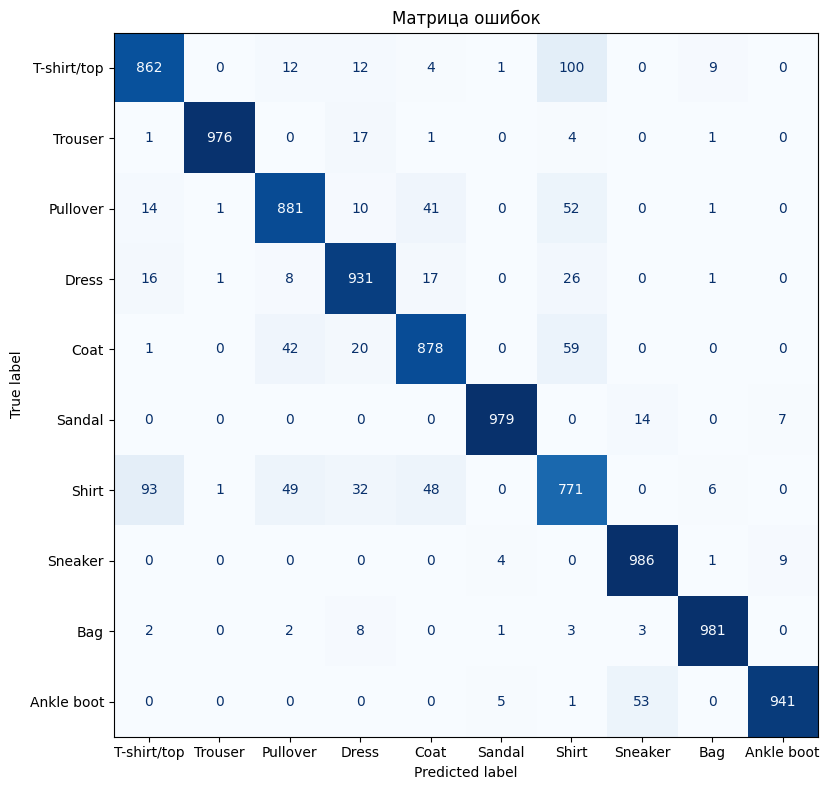

In [30]:
# Выполняем итоговую оценку выбранной модели на test.
from sklearn.metrics import classification_report
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

y_true, y_pred, y_probabilities = collect_predictions(best_model, test_loader, device)

print("\nПодробный отчёт:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(10)),
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0,
    )
)

# Количество объектов всех классов одинаково.
confusion = confusion_matrix(y_true, y_pred, labels=list(range(10)))

fig, ax = plt.subplots(figsize=(8.5, 8))
confusion_display = ConfusionMatrixDisplay(
    confusion_matrix=confusion,
    display_labels=CLASS_NAMES,
)
confusion_display.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title("Матрица ошибок")
plt.tight_layout()
plt.show()

## Контрольные вопросы

1. В чём состоит основное ограничение MLP при обработке изображений?
2. Что такое локальное рецептивное поле и пространственная локальность?
3. Как работает свёрточный слой и что называют ядром свёртки?
4. Что означают `in_channels` и `out_channels` в `nn.Conv2d`?
5. Как рассчитывается число параметров свёрточного слоя?
6. Как влияют `stride` и `padding` на размер выходного тензора?
7. Для чего используется pooling? Чем `MaxPool2d` отличается от свёрточного слоя?
8. Как изменяются формы тензоров в базовой CNN из этой работы?
9. Почему после двух блоков с pooling размер тензора перед `Linear` равен `64 * 7 * 7`?
10. Что такое переобучение? Как оно проявляется на графиках train/validation loss и accuracy?
11. Как работает Dropout и чем `nn.Dropout` отличается от `nn.Dropout2d`?
12. Почему Dropout отключается в режиме `eval()`?
13. Что нормализует `BatchNorm2d` и какие параметры он обучает?
14. Чем отличаются режимы `train()` и `eval()` для BatchNorm?
15. Почему перед оценкой модели необходимо переключать её в `eval()`?
16. Как CNN использует пространственную структуру изображения и разделение весов?
17. Всегда ли увеличение числа каналов или размера ядра повышает качество классификации?